## DATA 37711 HW 2
## Glen Morgenstern

### Problem 1(a)

The network $g:\mathbb{R}^p \to \mathbb{R}^2$ outputs two unconstrained real numbers,

$$
f_\mu(x) = g_1(x), \qquad f_\sigma(x) = \exp\big(g_2(x)\big)
$$

Reasoning why:
- $f_\mu(x) = \mathbb{E}[Y \mid X=x]$ can take any real valu, so no constraint is needed and the identify link is appropriate.
- $f_\sigma(x) = \sqrt{\mathrm{Var}(Y \mid X = x)}$ must be strictly positive. The exponential maps $\mathbb{R} to \to (0, \infty)$, so $g_2$ effectively models $\log \sigma$

### Problem 1(b)

Model. $Y \mid X = x \sim \mathcal{N}\big(f_\mu(x), f_\sigma(x)^2\big)$, so the density of one observation is

$$
p(y \mid x) = \frac{1}{f_\sigma(x)\sqrt{2\pi}} \exp\left( -\frac{(y - f_\mu(x))^2}{2 f_\sigma(x)^2} \right)
$$

Likelihood. Assuming the $n$ training pairs are independent,

$$
L(\theta) = \prod_{i=1}^{n} p(y_i \mid x_i)
$$

Log-likelihood. Taking the log turns the product into a sum:

$$
\log L(\theta) = \sum_{i=1}^{n} \left[ -\log f_\sigma(x_i) - \frac{1}{2}\log(2\pi) - \frac{(y_i - f_\mu(x_i))^2}{2 f_\sigma(x_i)^2} \right]
$$

Loss. Maximizing the likelihood is equivalent to minimizing the average negative log-likelihood:

$$
\mathcal{L}(\theta) = \frac{1}{n} \sum_{i=1}^{n} \left[ \log f_\sigma(x_i) + \frac{(y_i - f_\mu(x_i))^2}{2 f_\sigma(x_i)^2} \right] + \frac{1}{2}\log(2\pi)
$$

The constant $\frac{1}{2}\log(2\pi)$ does not depend on $\theta$ and can be dropped during optimization.


### Problem 1(c)

In [2]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet("taxi_trips.parquet")
X = df.drop(columns="trip_duration").values.astype("float32")
y = df["trip_duration"].values.astype("float32")

X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.3, random_state=50)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=50)

def gauss_nll(y, mu, sigma):
    return np.mean(np.log(sigma) + 0.5*np.log(2*np.pi) + (y - mu)**2 / (2*sigma**2))

# Baseline 1: constant Gaussian
mu0, s0 = y_tr.mean(), y_tr.std()
print("const  val NLL:", gauss_nll(y_va, mu0, s0))

# Baseline 2: linear mean, constant sigma (sigma = std of training residuals)
lin = LinearRegression().fit(X_tr, y_tr)
s1 = np.std(y_tr - lin.predict(X_tr))
print("linear  val NLL:", gauss_nll(y_va, lin.predict(X_va), s1))

const  val NLL: 3.458691786832291
linear  val NLL: 3.4313552717486635


In [3]:
import torch, torch.nn as nn

class GaussianMLP(nn.Module):
    def __init__(self, p=7, h=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(p, h), nn.ReLU(),
            nn.Linear(h, h), nn.ReLU(),
            nn.Linear(h, 2) # g(x) in R^2, from part a
        )
    def forward(self, x):
        out = self.net(x)
        return out[:,0], out[:, 1] # mean, log-sigma
    
def nll_loss(mu, log_sigma, y):
    return (log_sigma + 0.5 * ((y-mu) / torch.exp(log_sigma))**2).mean()

Our current bar to beat is 3.431 (baseline with linear mean, constant sigma). The linear model only improved validation NLL by 0.027 vs. constant Gaussian.

In [ ]:
import torch, torch.nn as nn
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)

#  standardize the target using TRAIN statistics only
ym, ys = y_tr.mean(), y_tr.std()
def to_t(a): return torch.tensor(a, dtype=torch.float32, device=device)
Xtr_t, Xva_t, Xte_t = to_t(X_tr), to_t(X_va), to_t(X_te)
ytr_t, yva_t = to_t((y_tr - ym) / ys), to_t((y_va - ym) / ys)

# model: hetero=True learns sigma(x); hetero=False learns one global sigma 
class GaussianMLP(nn.Module):
    def __init__(self, p=7, h=128, hetero=True):
        super().__init__()
        self.hetero = hetero
        self.net = nn.Sequential(nn.Linear(p, h), nn.ReLU(),
     nn.Linear(h, h), nn.ReLU(),
     nn.Linear(h, 2))
        self.const_log_sigma = nn.Parameter(torch.zeros(1))
    def forward(self, x):
        out = self.net(x)
        mu = out[:, 0]
        log_sigma = out[:, 1] if self.hetero else self.const_log_sigma.expand_as(mu)
        return mu, log_sigma

def nll_loss(mu, log_sigma, y):
    return (log_sigma + 0.5 * ((y - mu) / torch.exp(log_sigma))**2).mean()

#  training loop with early stopping 
def train(model, epochs=100, lr=1e-3, bs=1024, patience=10):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best, best_state, bad, n = float("inf"), None, 0, len(Xtr_t)
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(n, device=device)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            mu, ls = model(Xtr_t[idx])
            loss = nll_loss(mu, ls, ytr_t[idx])
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            val = nll_loss(*model(Xva_t), yva_t).item()
        print(f"epoch {epoch:3d}  val loss (standardized) {val:.4f}")
        if val < best - 1e-5:
            best, bad = val, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
  break
    model.load_state_dict(best_state)   # roll back to the best epoch
    return model

#  convert predictions back to minutes so NLL is comparable to baselines 
def predict(model, X):
    model.eval()
    with torch.no_grad():
        mu, ls = model(X)
    mu, ls = mu.detach().cpu().numpy(), ls.detach().cpu().numpy()
    return mu * ys + ym, np.exp(ls) * ys

def report(name, model):
    mu, sigma = predict(model, Xva_t)
    print(f"{name}: val NLL {gauss_nll(y_va, mu, sigma):.4f}, "
          f"val RMSE {np.sqrt(np.mean((y_va - mu)**2)):.3f}")

torch.manual_seed(0); m_const  = train(GaussianMLP(hetero=False)); report("MLP const sigma ", m_const)
torch.manual_seed(0); m_hetero = train(GaussianMLP(hetero=True));  report("MLP hetero sigma", m_hetero)

We see the MLP beats the linear model by a lot. NLL drops from 3.43 to 2.72. The heteroscedastic model wins on NLL ob 0.067 but loses on RMSE to the constant sigma model.

In [ ]:
mu_t, sig_t = predict(m_hetero, Xte_t)
mc, sc = predict(m_const, Xte_t)
print("const Gaussian :", gauss_nll(y_te, mu0, s0))
print("linear         :", gauss_nll(y_te, lin.predict(X_te), s1))
print("MLP const sigma:", gauss_nll(y_te, mc, sc))
print("MLP hetero     :", gauss_nll(y_te, mu_t, sig_t))

On the test data, hetero loses by 0.076.

### Problem 1(d)

For a new input $x$, the network gives us $f_\mu(x)$ and $f_\sigma(x)$.

$$
Y \mid X = x \sim \mathcal{N}\big(f_\mu(x), f_\sigma(x)^2\big).
$$

The probability that $Y$ falls below 45 is the area under this density to the left of 45. Standardizing $Y$ gives

$$
P(Y < 45 \mid X = x) = P\left(\frac{Y - f_\mu(x)}{f_\sigma(x)} < \frac{45 - f_\mu(x)}{f_\sigma(x)}\right) = \Phi\left(\frac{45 - f_\mu(x)}{f_\sigma(x)}\right),
$$

The step works because $(Y - f_\mu(x)) / f_\sigma(x)$ follows a standard normal distribution when $Y \mid X = x$ is normal.
Importantly, the predicted probability depends on both $f_\mu$ and $f_\sigma$. Two trips with the same predicted mean can receive different probabilities if the model is more uncertain about one of them. A model with constant $\sigma$ cannot express this.



### Problem 1(e)

In [ ]:
from scipy.stats import norm

z_tr = (y_tr < 45).astype(int)   # 1 = under 45 min
z_te = (y_te < 45).astype(int)

def evaluate(name, p):
    p = np.clip(p, 1e-12, 1 - 1e-12)          # avoid log(0)
    brier = np.mean((p - z_te)**2)
    ll    = -np.mean(z_te*np.log(p) + (1 - z_te)*np.log(1 - p))
    acc   = np.mean((p >= 0.5) == z_te)
    print(f"{name:24s} Brier {brier:.5f}  log-loss {ll:.5f}  acc {acc:.4f}")

n_te = len(y_te)
evaluate("always 'yes'",           np.ones(n_te))
evaluate("train base rate",        np.full(n_te, z_tr.mean()))
evaluate("linear, const sigma",    norm.cdf((45 - lin.predict(X_te)) / s1))
evaluate("MLP const sigma",        norm.cdf((45 - mc) / sc))
evaluate("MLP hetero sigma",       norm.cdf((45 - mu_t) / sig_t))

# Calibration sanity check: expected vs actual number of trips over 45 min
for name, p in {"MLP const": norm.cdf((45 - mc)/sc),
  "MLP hetero": norm.cdf((45 - mu_t)/sig_t)}.items():
    print(name, "expected # over 45:", round((1 - p).sum()), " actual:", (1 - z_te).sum())

- Accuracy is not informative here. Because about 99.55% of trips are under 45 minutes, a trivial classifier already achieves 99.55%. The MLPs improve this by only about 0.1 percentage points.
- The linear model is no better than the base rate on either proper scoring rule.
- Both MLPs improve Brier by roughly 30–35% over the base rate, with the constant-$\sigma$ model slightly ahead.
- Only the heteroscedastic model beats the base rate on log-loss (0.0227 vs 0.0288). The constant-$\sigma$ model is worse than the base rate on log-loss despite its better Brier score.

### Problem 2(a)

In [9]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("retail.csv")
for c in ["StockCode", "CustomerID"]:
    df[c] = df[c].astype(str).astype("category")   # str first so 17850.0 and "85123A" are both plain labels

for c in ["StockCode", "CustomerID"]:
    print(c, "unique:", df[c].nunique())
print("one-hot width:", df["StockCode"].nunique() + df["CustomerID"].nunique())

tr, tmp = train_test_split(df, test_size=0.30, random_state=0)
va, te = train_test_split(tmp, test_size=0.50, random_state=0)
print(len(tr), len(va), len(te))

# how many val/test rows have a category never seen in training?
for c in ["StockCode", "CustomerID"]:
    seen = set(tr[c].astype(str))
    for name, part in [("val", va), ("test", te)]:
        unseen = (~part[c].astype(str).isin(seen)).mean()
        print(f"{c} unseen in {name}: {unseen:.2%} of rows")

StockCode unique: 3665
CustomerID unique: 4339
one-hot width: 8004
278546 59689 59689
StockCode unseen in val: 0.07% of rows
StockCode unseen in test: 0.05% of rows
CustomerID unseen in val: 0.04% of rows
CustomerID unseen in test: 0.04% of rows


Cardinality. StockCode has 3,665 unique values and CustomerID has 4,339, across 397,924 transactions. Both are high-cardinality with a long tail. The median category has about 40-50 rows, but about 15% of products and 7% of customers have five or fewer, and 4.6% of prodcuts and 1.7% of customers appear exactly once.

Is one-hot encoding feasible? It would produce 3,665 + 4,339 = 8,004 columns. That is a huge matrix, which is impractical. A sparse representation could fit, but it remains a poor representation. The model has a learn a separate weight for each of more than 8,000 columns, and estimate it from very few rows for the rare categories. So we would want compact encodings: taret encoding (one number per category) and learned embeddings (a short vector per category).


### Problem 2(b)

In [ ]:
import category_encoders as ce
import torch, torch.nn as nn
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)

cols = ["StockCode", "CustomerID"]
ytr, yva, yte = [np.log(d["Quantity"].values).astype("float32") for d in (tr, va, te)]

#  target encoding: fit on TRAIN only, apply to all splits 
enc = ce.TargetEncoder(cols=cols, min_samples_leaf=20, smoothing=10)
enc.fit(tr[cols].astype(str), ytr)
Xtr, Xva, Xte = [enc.transform(d[cols].astype(str)).values.astype("float32")
   for d in (tr, va, te)]

#  baselines (validation RMSE on the log scale) 
rmse = lambda a, b: np.sqrt(np.mean((a - b)**2))
print("global mean         :", rmse(yva, ytr.mean()))
print("StockCode encoding  :", rmse(yva, Xva[:, 0]))
print("CustomerID encoding :", rmse(yva, Xva[:, 1]))

#  MLP on the two encoded features 
class MLP(nn.Module):
    def __init__(self, p=2, h=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(p, h), nn.ReLU(),
     nn.Linear(h, h), nn.ReLU(),
     nn.Linear(h, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

def fit_mlp(model, Xtr, ytr, Xva, yva, epochs=100, lr=1e-3, bs=1024, patience=10):
    Xtr, ytr, Xva, yva = [torch.tensor(a, device=device) for a in (Xtr, ytr, Xva, yva)]
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best, best_state, bad = float("inf"), None, 0
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i + bs]
            loss = ((model(Xtr[idx]) - ytr[idx])**2).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val = ((model(Xva) - yva)**2).mean().item()
        if val < best - 1e-5:
            best, bad = val, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
  break
    print(f"stopped after {epoch + 1} epochs, best val MSE {best:.4f}")
    model.load_state_dict(best_state)
    return model

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, device=device)).cpu().numpy()

m_te = fit_mlp(MLP(), Xtr, ytr, Xva, yva)
print("target-enc MLP val RMSE (log):", rmse(yva, predict(m_te, Xva)))

The combination of target encodings on both StockCode and CustomerID beats either alone by a fairly wide margin (0.881 to 0.709). So the model is using both features together, not just picking the better one.

### Problem 2(c)

In [12]:
def make_index(train_col):
    cats = sorted(train_col.astype(str).unique())
    return {c: i + 1 for i, c in enumerate(cats)}

maps = {c: make_index(tr[c]) for c in cols}

def to_idx(d):
    return np.stack([d[c].astype(str).map(maps[c]).fillna(0).astype("int64").values for c in cols], axis=1)
    
Itr,Iva, Ite = to_idx(tr), to_idx(va), to_idx(te)

In [ ]:
class EmbMLP(nn.Module):
    def __init__(self, n_stock, n_cust, d=16, h=64):
        super().__init__()
        self.e_stock = nn.Embedding(n_stock + 1, d, padding_idx=0)
        self.e_cust  = nn.Embedding(n_cust + 1,  d, padding_idx=0)
        self.net = nn.Sequential(nn.Linear(2 * d, h), nn.ReLU(),
     nn.Linear(h, h), nn.ReLU(),
     nn.Linear(h, 1))
    
    def forward(self,idx):
        z = torch.cat([self.e_stock(idx[:,0]), self.e_cust(idx[:,1])], dim=1)
        return self.net(z).squeeze(-1)

torch.manual_seed(0)
m_emb = fit_mlp(EmbMLP(len(maps["StockCode"]), len(maps["CustomerID"])), Itr, ytr, Iva, yva)
print("embedding MLP val RMSE (log):", rmse(yva, predict(m_emb, Iva)))

stopped after 40 epochs, best val MSE 0.4330
embedding MLP val RMSE (log): 0.6579998


In [ ]:
cnt_s = tr["StockCode"].astype(str).value_counts()
cnt_c = tr["CustomerID"].astype(str).value_counts()
n_s = va["StockCode"].astype(str).map(cnt_s).fillna(0).values
n_c = va["CustomerID"].astype(str).map(cnt_c).fillna(0).values
min_n = np.minimum(n_s, n_c)           # rarity of the rarer of the two categories

p_te  = predict(m_te,  Xva)
p_emb = predict(m_emb, Iva)
for lo, hi in [(0, 5), (5, 20), (20, 100), (100, 10**9)]:
    m = (min_n >= lo) & (min_n < hi)
    print(f"rarest category has {lo}-{hi} train rows: n={m.sum():6d}  "
          f"target-enc {rmse(yva[m], p_te[m]):.3f}   embedding {rmse(yva[m], p_emb[m]):.3f}")

The embedding model is better in every bucket, with the largest gain for categories with 5-20 training rows.

### Problem 2(d)

In [ ]:
class BothMLP(nn.Module):
    def __init__(self, n_stock, n_cust, d=16, h=64):
        super().__init__()
        self.e_stock = nn.Embedding(n_stock + 1, d, padding_idx=0)
        self.e_cust  = nn.Embedding(n_cust + 1,  d, padding_idx=0)
        self.net = nn.Sequential(nn.Linear(2 * d + 2, h), nn.ReLU(),
     nn.Linear(h, h), nn.ReLU(),
     nn.Linear(h, 1))
    def forward(self, x):
        idx, enc = x[:, :2].long(), x[:, 2:]
        z = torch.cat([self.e_stock(idx[:, 0]), self.e_cust(idx[:, 1]), enc], dim=1)
        return self.net(z).squeeze(-1)

# pack [stock_idx, cust_idx, stock_enc, cust_enc] into one float32 array
pack = lambda I, X: np.hstack([I.astype("float32"), X])
Btr, Bva, Bte = pack(Itr, Xtr), pack(Iva, Xva), pack(Ite, Xte)

torch.manual_seed(0)
m_both = fit_mlp(BothMLP(len(maps["StockCode"]), len(maps["CustomerID"])),
   Btr, ytr, Bva, yva)
print("combined MLP val RMSE (log):", rmse(yva, predict(m_both, Bva)))

stopped after 38 epochs, best val MSE 0.4226
combined MLP val RMSE (log): 0.6501141


In [ ]:
p_both = predict(m_both, Bva)
for lo, hi in [(0, 5), (5, 20), (20, 100), (100, 10**9)]:
    m = (min_n >= lo) & (min_n < hi)
    print(f"{lo}-{hi} rows: target-enc {rmse(yva[m], p_te[m]):.3f}  "
          f"embedding {rmse(yva[m], p_emb[m]):.3f}  combined {rmse(yva[m], p_both[m]):.3f}")

In [18]:
print("global mean       :", rmse(yte, ytr.mean()))
print("target-enc MLP    :", rmse(yte, predict(m_te,   Xte)))
print("embedding MLP     :", rmse(yte, predict(m_emb,  Ite)))
print("combined MLP      :", rmse(yte, predict(m_both, Bte)))

global mean       : 1.21371
target-enc MLP    : 0.71879435
embedding MLP     : 0.6653863
combined MLP      : 0.6610823


Overall, the combined method produces the lowest squared test error, though not by a lot compared to either target encoding or embedding MLP separately. This was consistent with the validation error rankings as well. The gain is largest for the rarest categories, where the smoothed encoding might give a prior that embeddings cannot learn from very few rows, and small or slightly negative for categories with 5-20 rows, where leakage of each training row's own target into its encoding could encourage over-reliance on that feature.

### Problem 2(e)

Experiment 1: linear probe from embedding category mean. Does the embedding contan the category's mean quantity? If you can predict a category's mean log-quantity from its 16 numbers witha simple linear model, the embedding has learned something like traget encoding on its own. A moderate R^2 would mean the vectors hold that info plus other things.

In [19]:
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import cross_val_predict, KFold

def probe(emb, col):
    s = tr[col].astype(str)
    cats = sorted(s.unique())  # same order as the index map (row i+1 of the table)
    t_all = pd.Series(ytr, index=s.values).groupby(level=0).mean().reindex(cats).values
    n_all = s.value_counts().reindex(cats).values
    keep = n_all >= 20  # only categories with well-estimated means
    E, t = emb[keep], t_all[keep]
    pred = cross_val_predict(RidgeCV(alphas=np.logspace(-2, 3, 12)), E, t,
 cv=KFold(5, shuffle=True, random_state=0))
    r2 = 1 - ((t - pred)**2).sum() / ((t - t.mean())**2).sum()
    print(f"{col}: {keep.sum()} categories, R^2 (embedding -> category mean) = {r2:.3f}")

probe(m_emb.e_stock.weight.detach().cpu().numpy()[1:], "StockCode")   # [1:] drops the "unseen" row
probe(m_emb.e_cust.weight.detach().cpu().numpy()[1:],  "CustomerID")

StockCode: 2271 categories, R^2 (embedding -> category mean) = 0.100
CustomerID: 2672 categories, R^2 (embedding -> category mean) = 0.144


Experiment 2: scramble embeddings on the test set. Does the model actually use each embedding, and how much? Scramble the product indices on the test set, so each row gets another row's vector, and see how much test RMSE degrades. A big jump means the model relies on that feature.

In [20]:
rng = np.random.default_rng(0)
base = rmse(yte, predict(m_emb, Ite))
print("intact          :", base)
for j, name in [(0, "product"), (1, "customer")]:
    I = Ite.copy()
    I[:, j] = rng.permutation(I[:, j]) # each row gets another row's category
    print(f"scrambled {name:9s}:", rmse(yte, predict(m_emb, I)))
I = Ite.copy(); I[:, 0] = rng.permutation(I[:, 0]); I[:, 1] = rng.permutation(I[:, 1])
print("scrambled both  :", rmse(yte, predict(m_emb, I)))

intact          : 0.6653863
scrambled product  : 1.0987173
scrambled customer : 1.3915309
scrambled both  : 1.6082594


Experiment 3: how far did each vector move form its random start? Do rare categories get protected from memorization? We'll measure how far each category's vector moved from its random starting point, against how many training rows it has.If rare categories barely moved, that is implicit regularization, which would explain why embeddings did better than expected on the rare buckets.

In [ ]:
from scipy.stats import spearmanr
torch.manual_seed(0) # reproduces the initial weights used in part (c)
init = EmbMLP(len(maps["StockCode"]), len(maps["CustomerID"]))
for name, col, a, b in [("product", "StockCode", m_emb.e_stock, init.e_stock),
         ("customer", "CustomerID", m_emb.e_cust, init.e_cust)]:
    moved = (a.weight.detach().cpu() - b.weight.detach().cpu()).norm(dim=1).numpy()[1:]
    cats = sorted(tr[col].astype(str).unique())
    n = tr[col].astype(str).value_counts().reindex(cats).values
    print(f"{name}: median distance moved {np.median(moved):.2f}; "
          f"Spearman(log count, moved) = {spearmanr(np.log(n), moved)[0]:.2f}")
    for lo, hi in [(1, 5), (5, 20), (20, 100), (100, 10**9)]:
        m = (n >= lo) & (n < hi)
        if m.any():
            print(f"   {lo}-{hi} train rows: n={m.sum():5d}, median moved {np.median(moved[m]):.2f}")

product: median distance moved 1.08; Spearman(log count, moved) = 0.05
   1-5 train rows: n=  558, median moved 1.06
   5-20 train rows: n=  778, median moved 1.07
   20-100 train rows: n= 1395, median moved 1.08
   100-1000000000 train rows: n=  876, median moved 1.10
customer: median distance moved 0.92; Spearman(log count, moved) = 0.09
   1-5 train rows: n=  350, median moved 1.02
   5-20 train rows: n= 1282, median moved 0.85
   20-100 train rows: n= 1960, median moved 0.94
   100-1000000000 train rows: n=  712, median moved 0.97


**Experiment 1:** I fit a ridge regression from each category's embedding vector to its training mean log-quantity (categories with at least 20 training rows, 5-fold cross-validation split by category). Cross-validated $R^2$ was 0.10 for products and 0.14 for customers, so the mean log-quantity is not linearly recoverable from the trained vectors. This result is partly confounded by initialization: the vectors begin as random normal vectors (norm about 4) and moved a median of only about 1 unit during training.

**Experiment 2:** I permuted the category indices across test rows, giving each row another row's embedding. The model depends strongly on both embeddings, more on customers, consistent with the customer target encoding being the stronger single predictor in part (b). Permuting customers or both gives worse error than the global-mean baseline (1.214), since the network produces confidently wrong predictions from mismatched vectors. Permutation measures reliance, not information content, and also destroys product–customer pairing.

**Experiment 3:** I measured the distance between each trained embedding and its initial value. Median movement was about 1.0–1.1 in all frequency buckets (Spearman correlation with log training count: 0.05 for products, 0.09 for customers). Rare categories were therefore not less trained, so we do not find evidence that embeddings are implicitly regularized by under-training rare categories.

Overall, the embeddings are acting as a learned, high-capacity identity code that the network relies on heavily, and they carry information beyond a linearly readable category mean.

Embeddings give each of the thousands of products and customers a short learned vector instead of a single mean (target encoding) or an unusable 8,004-column one-hot, so the network can keep whatever about a category helps predict quantity and combine the customer and product vectors nonlinearly. This fits the results: the embedding model beat the target-encoded one on test (RMSE 0.665 vs. 0.719), though I haven’t isolated how much of that gap comes from the richer representation versus the encoder’s untuned smoothing.


### Problem 3(a)

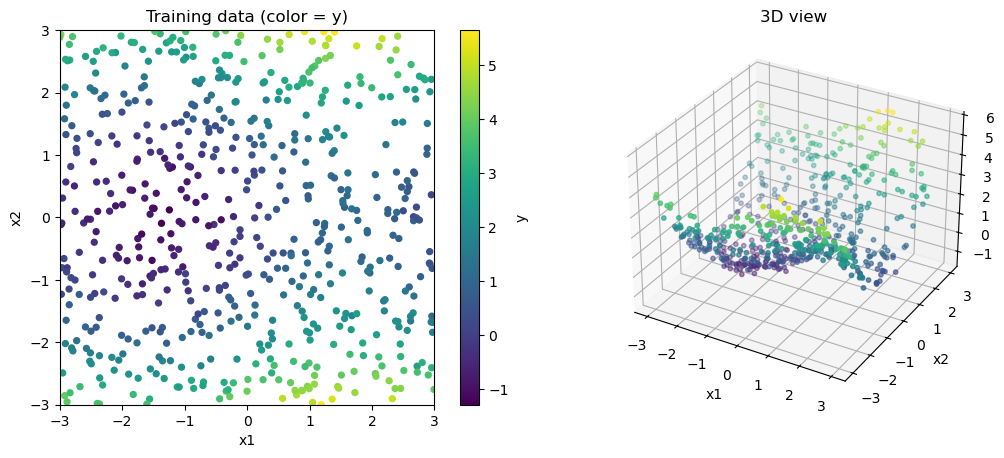

In [22]:
import matplotlib.pyplot as plt
from dataloader import HW2Dataset

ds = HW2Dataset.from_csv("train.csv", "val.csv", "test.csv")
Xtr, ytr = ds.train.X, ds.train.y
Xva, yva = ds.val.X, ds.val.y
Xte = ds.test.X

fig = plt.figure(figsize=(11, 4.5))

ax = fig.add_subplot(1, 2, 1)
sc = ax.scatter(Xtr[:, 0], Xtr[:, 1], c=ytr, s=18, cmap="viridis")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title("Training data (color = y)")
ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
fig.colorbar(sc, ax=ax, label="y")

ax3 = fig.add_subplot(1, 2, 2, projection="3d")
ax3.scatter(Xtr[:, 0], Xtr[:, 1], ytr, c=ytr, s=10, cmap="viridis")
ax3.set_xlabel("x1"); ax3.set_ylabel("x2"); ax3.set_zlabel("y"); ax3.set_title("3D view")

plt.tight_layout(); plt.savefig("train_data.png", dpi=200); plt.show()

We see a bowl shape. The underlying function appears smooth and low-frequency, so we expect the best models to use smooth features. Overfitting could be a concern here.

### Problem 3(b)

In [23]:
class RandomKitchenSinks:
    def __init__(self, D=500, sigma=1.0, ridge_lambda=1.0, d_in=2, seed=0):
        assert D % 2 == 0, "D must be even (sin and cos pairs)"
        self.D, self.sigma, self.lam = D, sigma, ridge_lambda
        h = D // 2  # number of (sin, cos) pairs
        rng = np.random.default_rng(seed)
        self.W = rng.normal(size=(d_in, h)) / sigma  # each column is one w_j ~ N(0, I/sigma^2)
        self.b = rng.uniform(0, 2 * np.pi, size=h)  # b_j ~ U[0, 2pi]

    def _features(self, X):
        proj = X @ self.W + self.b  # (n, h): w_j^T x_i + b_j for every i, j
        return np.hstack([np.sin(proj), np.cos(proj)])  # (n, D)

    def fit(self, X, y):
        self.y_mean_ = y.mean() # handles the intercept
        phi = self._features(X)
        A = phi.T @ phi + self.lam * np.eye(self.D)
        self.coef_ = np.linalg.solve(A, phi.T @ (y - self.y_mean_))
        return self

    def predict(self, X):
        return self._features(X) @ self.coef_ + self.y_mean_

def mse(a, b):
    return np.mean((a - b) ** 2)

best sigma by validation MSE: 3.1622776601683795  val MSE: 0.03555508315425302


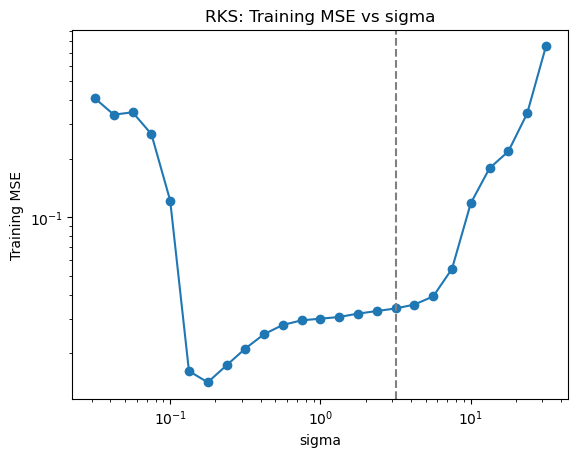

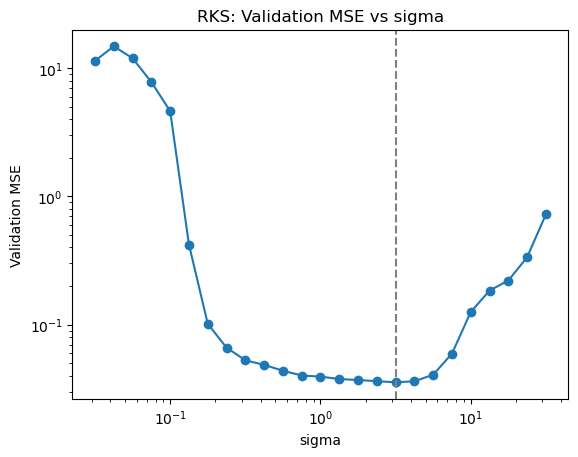

In [24]:
ds = HW2Dataset.from_csv("train.csv", "val.csv", "test.csv")
Xtr, ytr, Xva, yva = ds.train.X, ds.train.y, ds.val.X, ds.val.y

sigmas = np.logspace(-1.5, 1.5, 25)
tr_mse, va_mse = [], []
for s in sigmas:
    m = RandomKitchenSinks(D=500, sigma=s, ridge_lambda=1.0).fit(Xtr, ytr)
    tr_mse.append(mse(ytr, m.predict(Xtr)))
    va_mse.append(mse(yva, m.predict(Xva)))

best_sigma = sigmas[int(np.argmin(va_mse))]
print("best sigma by validation MSE:", best_sigma, " val MSE:", min(va_mse))

for losses, name in [(tr_mse, "Training"), (va_mse, "Validation")]:
    plt.figure()
    plt.loglog(sigmas, losses, "o-")
    plt.xlabel("sigma"); plt.ylabel(f"{name} MSE"); plt.title(f"RKS: {name} MSE vs sigma")
    plt.axvline(best_sigma, ls="--", c="gray")
    plt.savefig(f"rks_{name.lower()}_sweep.png", dpi=200)
plt.show()

We choose sigma by validation MSE here, since training MSE is really prone to overfitting.

### Problem 3(c)

I'll sweep over width here.

In [ ]:
class MLP(nn.Module):
    def __init__(self, d_in=2, d_hidden=128, d_out=1, lr=1e-2, batch_size=64,
                 epochs=300, device="cpu", seed=0):
        super().__init__()
        self.device, self.lr, self.batch_size = device, lr, batch_size
        self.epochs, self.seed = epochs, seed
        torch.manual_seed(seed)   # fixes the random initial weights
        self.net = nn.Sequential(
            nn.Linear(d_in, d_hidden), nn.ReLU(),  # d_hidden folds
            nn.Linear(d_hidden, d_out),  # weighted sum of the folds
        ).to(device)

    def forward(self, X):
        return self.net(X)

    def fit(self, X, y):
        X = torch.from_numpy(X).float().to(self.device)
        y = torch.from_numpy(y).float().view(-1, 1).to(self.device)
        opt = torch.optim.Adam(self.net.parameters(), lr=self.lr)
        loss_fn = nn.MSELoss()
        g = torch.Generator().manual_seed(self.seed)  # fixes the batch shuffling too
        n = len(X)
        self.net.train()
        for epoch in range(self.epochs):
            perm = torch.randperm(n, generator=g)
            for i in range(0, n, self.batch_size):
                idx = perm[i:i + self.batch_size]
                loss = loss_fn(self.net(X[idx]), y[idx])
                opt.zero_grad(); loss.backward(); opt.step()
        self.net.eval()
        return self

    def predict(self, X):
        with torch.no_grad():
            X = torch.from_numpy(X).float().to(self.device)
            return self.forward(X).cpu().numpy().ravel()

mse = lambda a, b: np.mean((a - b) ** 2)

In [ ]:
ds = HW2Dataset.from_csv("train.csv", "val.csv", "test.csv")
Xtr, ytr, Xva, yva = ds.train.X, ds.train.y, ds.val.X, ds.val.y

widths = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1028]
seeds = [0, 1, 2]
tr = np.zeros((len(seeds), len(widths)))
va = np.zeros((len(seeds), len(widths)))
for i, s in enumerate(seeds):
    for j, w in enumerate(widths):
        m = MLP(d_hidden=w, seed=s).fit(Xtr, ytr)
        tr[i, j], va[i, j] = mse(ytr, m.predict(Xtr)), mse(yva, m.predict(Xva))

tr_m, va_m = tr.mean(0), va.mean(0)
best_w = widths[int(np.argmin(va_m))]
print("best width:", best_w, " mean val MSE:", va_m.min())
print("val MSE by seed at best width:", va[:, widths.index(best_w)])

for curves, mean, name in [(tr, tr_m, "Training"), (va, va_m, "Validation")]:
    plt.figure()
    plt.loglog(widths, curves.T, color="lightgray", lw=1)   # individual seeds
    plt.loglog(widths, mean, "o-")  # mean over seeds
    plt.xlabel("hidden width"); plt.ylabel(f"{name} MSE")
    plt.title(f"MLP: {name} MSE vs width"); plt.axvline(best_w, ls="--", c="gray")
    plt.savefig(f"mlp_{name.lower()}_sweep.png", dpi=200)
plt.show()

Each hidden unit contributes one "fold" (a ramp along one direction), so the network is a piecewise-linear surface with at most $h$ folds. A width-1 network can only represent a tilted ramp and cannot capture the curvature of the bowl-shaped data (validation MSE about 1.8, comparable to a plane fit at 2.06), so it underfits. Error falls as more folds become available to tile the bowl. At the large-width end we see no evidence of overfitting in the range tested: validation MSE does not rise, and the gap between training and validation MSE stays small and roughly constant.